In [29]:

# STEP 1: Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neural_network import MLPClassifier

np.random.seed(42)



Implement activation functions

In [30]:
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def softmax(x):
    x = x - np.max(x, axis=-1, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

# Test functions
x = np.array([-2, -1, 0, 1, 2])

print("Input:  ", x)
print("Sigmoid:", sigmoid(x))
print("Tanh:   ", tanh(x))
print("ReLU:   ", relu(x))
print("Softmax:", softmax(x))
print("Softmax sum:", softmax(x).sum())


Input:   [-2 -1  0  1  2]
Sigmoid: [0.119 0.269 0.5   0.731 0.881]
Tanh:    [-0.964 -0.762  0.     0.762  0.964]
ReLU:    [0 0 0 1 2]
Softmax: [0.012 0.032 0.086 0.234 0.636]
Softmax sum: 1.0


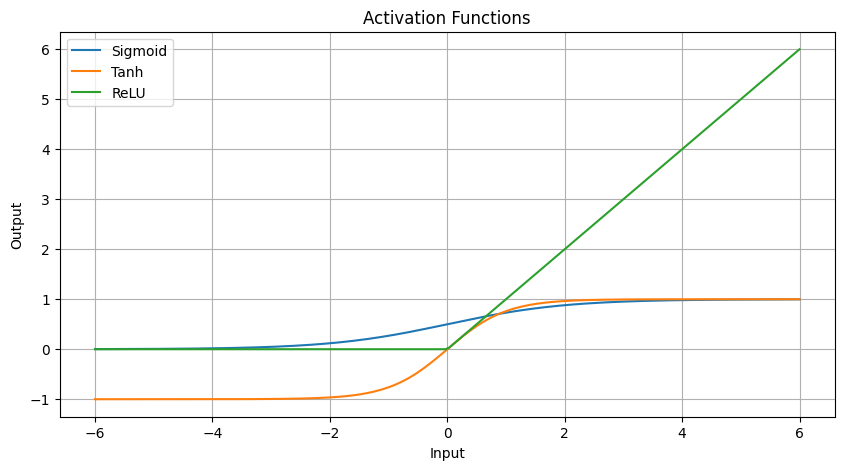

In [31]:

x = np.linspace(-6, 6, 200)

plt.figure(figsize=(10, 5))
plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, tanh(x), label="Tanh")
plt.plot(x, relu(x), label="ReLU")

plt.title("Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")
plt.legend()
plt.grid(True)
plt.show()


Implement loss functions

In [32]:
def mse(y_true, y_pred):
    return np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)

def binary_cross_entropy(y_true, y_prob):
    eps = 1e-7
    y_prob = np.clip(y_prob, eps, 1 - eps)

    return -np.mean(
        y_true * np.log(y_prob)
        + (1 - y_true) * np.log(1 - y_prob)
    )

# Example
y_true = np.array([0, 1, 1, 0])
y_pred = np.array([0.1, 0.8, 0.7, 0.2])

print("MSE:", mse(y_true, y_pred))
print("Binary Cross-Entropy:",
      binary_cross_entropy(y_true, y_pred))


MSE: 0.045000000000000005
Binary Cross-Entropy: 0.22708064055624455


Implement gradient descent from scratch

In [33]:
np.random.seed(42)

X = np.linspace(-2, 2, 100)
y = 3 * X + 1 + np.random.normal(0, 0.3, 100)

# Initialize parameters
w = 0.0
b = 0.0

learning_rate = 0.05
epochs = 300
loss_history = []

for epoch in range(epochs):

    # Forward propagation
    y_pred = w * X + b

    # Calculate error and loss
    error = y_pred - y
    loss = np.mean(error ** 2)
    loss_history.append(loss)

    # Calculate gradients
    dw = 2 * np.mean(error * X)
    db = 2 * np.mean(error)

    # Update parameters
    w -= learning_rate * dw
    b -= learning_rate * db

print("Learned weight:", round(w, 3))
print("Learned bias:", round(b, 3))
print("Final loss:", round(loss_history[-1], 5))


Learned weight: 3.01
Learned bias: 0.969
Final loss: 0.07334


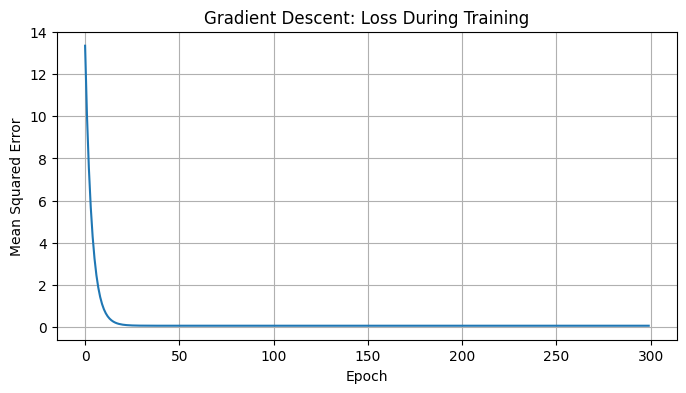

In [34]:

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Gradient Descent: Loss During Training")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.show()


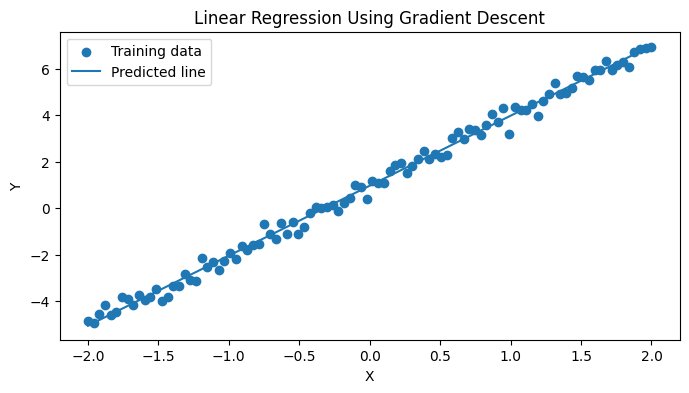

In [35]:

plt.figure(figsize=(8, 4))
plt.scatter(X, y, label="Training data")
plt.plot(X, w * X + b, label="Predicted line")
plt.title("Linear Regression Using Gradient Descent")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()


Implement optimization algorithms

SGD final parameter: 0.008985
Momentum final parameter: 0.190347
RMSProp final parameter: 0.159742
Adam final parameter: 0.484529


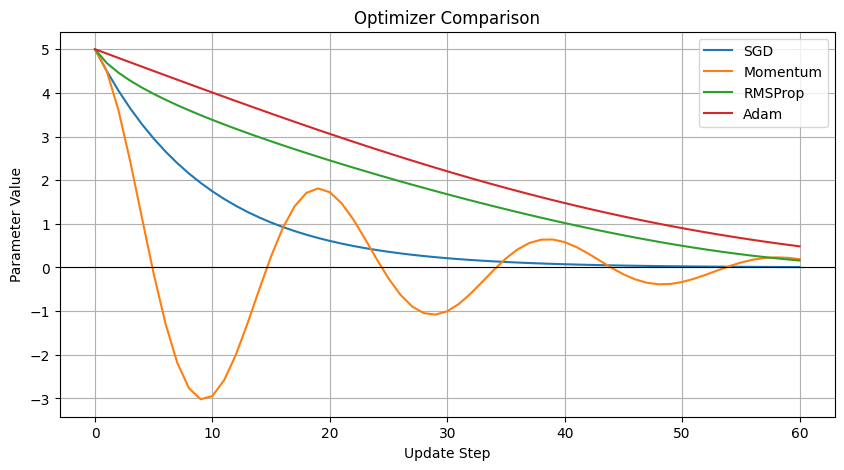

In [37]:
def optimize(optimizer, learning_rate=0.1, steps=60):

    theta = 5.0
    momentum = 0.0
    velocity = 0.0

    beta1 = 0.9
    beta2 = 0.999
    epsilon = 1e-8

    history = [theta]

    for t in range(1, steps + 1):

        # Gradient of 0.5 * theta^2
        grad = theta

        if optimizer == "SGD":
            theta -= learning_rate * grad

        elif optimizer == "Momentum":
            momentum = 0.9 * momentum + grad
            theta -= learning_rate * momentum

        elif optimizer == "RMSProp":
            velocity = 0.9 * velocity + 0.1 * grad**2
            theta -= learning_rate * grad / (
                np.sqrt(velocity) + epsilon
            )

        elif optimizer == "Adam":
            momentum = beta1 * momentum + (1-beta1) * grad
            velocity = beta2 * velocity + (1-beta2) * grad**2

            m_hat = momentum / (1-beta1**t)
            v_hat = velocity / (1-beta2**t)

            theta -= learning_rate * m_hat / (
                np.sqrt(v_hat) + epsilon
            )

        history.append(theta)

    return history


# Run each optimizer
optimizers = ["SGD", "Momentum", "RMSProp", "Adam"]

plt.figure(figsize=(10, 5))

for name in optimizers:
    history = optimize(name)
    plt.plot(history, label=name)
    print(name, "final parameter:", round(history[-1], 6))

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Optimizer Comparison")
plt.xlabel("Update Step")
plt.ylabel("Parameter Value")
plt.legend()
plt.grid(True)
plt.show()


Split the dataset into training, validation, and test sets

In [38]:

# STEP 6: Prepare and split data

X, y = make_classification(
    n_samples=1200,
    n_features=12,
    n_informative=7,
    n_redundant=2,
    random_state=42
)

# First split: 60% training, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: 20% validation, 20% test overall
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("Training percentage:",
      round(len(X_train) / len(X) * 100, 1), "%")
print("Validation percentage:",
      round(len(X_val) / len(X) * 100, 1), "%")
print("Test percentage:",
      round(len(X_test) / len(X) * 100, 1), "%")


Training samples: 720
Validation samples: 240
Test samples: 240
Training percentage: 60.0 %
Validation percentage: 20.0 %
Test percentage: 20.0 %


In [39]:

# Scale the features without leaking validation/test data

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Create and train a neural network
model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=500,
    early_stopping=True,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# Evaluate
val_predictions = model.predict(X_val_scaled)
test_predictions = model.predict(X_test_scaled)

print("Validation accuracy:",
      round(accuracy_score(y_val, val_predictions), 4))

print("Test accuracy:",
      round(accuracy_score(y_test, test_predictions), 4))

print("\nTest classification report:")
print(classification_report(y_test, test_predictions))


Validation accuracy: 0.8083
Test accuracy: 0.8167

Test classification report:
              precision    recall  f1-score   support

           0       0.82      0.82      0.82       120
           1       0.82      0.82      0.82       120

    accuracy                           0.82       240
   macro avg       0.82      0.82      0.82       240
weighted avg       0.82      0.82      0.82       240



Build a neural network from scratch

In [40]:

# STEP 7.1: Create a nonlinear dataset

X_nn, y_nn = make_moons(
    n_samples=1000,
    noise=0.20,
    random_state=42
)

# Scale the input features
scaler_nn = StandardScaler()
X_nn = scaler_nn.fit_transform(X_nn)

# Convert labels to a column vector
y_nn = y_nn.reshape(-1, 1)

# Split training and testing data
Xtr, Xte, ytr, yte = train_test_split(
    X_nn,
    y_nn,
    test_size=0.20,
    random_state=42,
    stratify=y_nn
)

print("Training shape:", Xtr.shape)
print("Testing shape:", Xte.shape)


Training shape: (800, 2)
Testing shape: (200, 2)


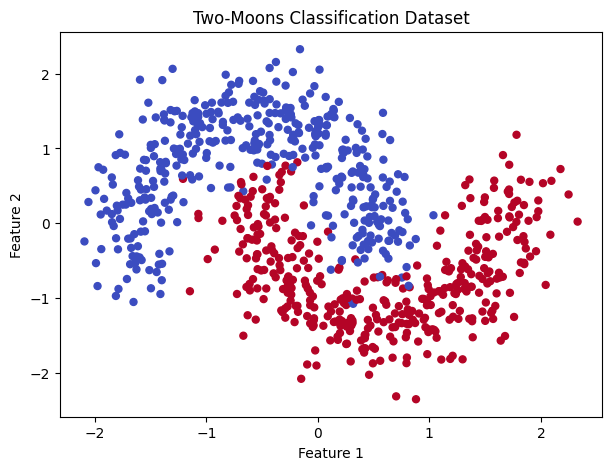

In [41]:

plt.figure(figsize=(7, 5))

plt.scatter(
    Xtr[:, 0], Xtr[:, 1],
    c=ytr.ravel(),
    cmap="coolwarm",
    s=25
)

plt.title("Two-Moons Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [42]:

# STEP 7.2: Initialize weights and biases

def initialize_network(n_inputs=2, n_hidden=16):

    rng = np.random.default_rng(42)

    params = {
        "W1": rng.normal(
            0, np.sqrt(2 / n_inputs),
            (n_inputs, n_hidden)
        ),
        "b1": np.zeros((1, n_hidden)),

        "W2": rng.normal(
            0, np.sqrt(2 / n_hidden),
            (n_hidden, 1)
        ),
        "b2": np.zeros((1, 1))
    }

    return params


params = initialize_network()

for name, value in params.items():
    print(name, value.shape)


W1 (2, 16)
b1 (1, 16)
W2 (16, 1)
b2 (1, 1)


Implement forward propagation

In [43]:

# STEP 7.3: Forward propagation

def forward_propagation(X, params):

    # Hidden layer
    z1 = X @ params["W1"] + params["b1"]
    a1 = relu(z1)

    # Output layer
    z2 = a1 @ params["W2"] + params["b2"]
    a2 = sigmoid(z2)

    # Save values needed for backpropagation
    cache = (X, z1, a1, a2)

    return a2, cache


# Test the forward pass
sample_predictions, cache = forward_propagation(
    Xtr[:5], params
)

print("Predicted probabilities:")
print(sample_predictions)

print("\nActual labels:")
print(ytr[:5])


Predicted probabilities:
[[0.413]
 [0.585]
 [0.736]
 [0.307]
 [0.676]]

Actual labels:
[[1]
 [0]
 [1]
 [0]
 [1]]


Train using backpropagation

In [45]:
def train_neural_network(
    X, y,
    hidden=16,
    learning_rate=0.05,
    epochs=2500
):

    params = initialize_network(
        n_inputs=X.shape[1],
        n_hidden=hidden
    )

    loss_history = []
    m = len(X)

    for epoch in range(epochs):

        # ----- Forward propagation -----
        a2, cache = forward_propagation(X, params)
        Xb, z1, a1, a2 = cache

        # Binary cross-entropy loss
        loss = binary_cross_entropy(y, a2)
        loss_history.append(loss)

        # ----- Backpropagation -----

        # Output layer gradient
        dz2 = (a2 - y) / m
        dW2 = a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        # Hidden layer gradient
        da1 = dz2 @ params["W2"].T
        dz1 = da1 * (z1 > 0)

        dW1 = Xb.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        # ----- Update weights and biases -----
        params["W2"] -= learning_rate * dW2
        params["b2"] -= learning_rate * db2

        params["W1"] -= learning_rate * dW1
        params["b1"] -= learning_rate * db1

    return params, loss_history


params, loss_history = train_neural_network(
    Xtr, ytr,
    hidden=16,
    learning_rate=0.05,
    epochs=2500
)

print("Training complete!")
print("Initial loss:", round(loss_history[0], 4))
print("Final loss:", round(loss_history[-1], 4))


Training complete!
Initial loss: 0.6939
Final loss: 0.115


Evaluate the neural network

In [46]:

# STEP 7.5: Evaluate model performance

train_prob, _ = forward_propagation(Xtr, params)
test_prob, _ = forward_propagation(Xte, params)

train_pred = (train_prob >= 0.5).astype(int)
test_pred = (test_prob >= 0.5).astype(int)

train_accuracy = accuracy_score(
    ytr.ravel(), train_pred.ravel()
)

test_accuracy = accuracy_score(
    yte.ravel(), test_pred.ravel()
)

print("Training accuracy:", round(train_accuracy, 4))
print("Testing accuracy:", round(test_accuracy, 4))


Training accuracy: 0.9637
Testing accuracy: 0.975


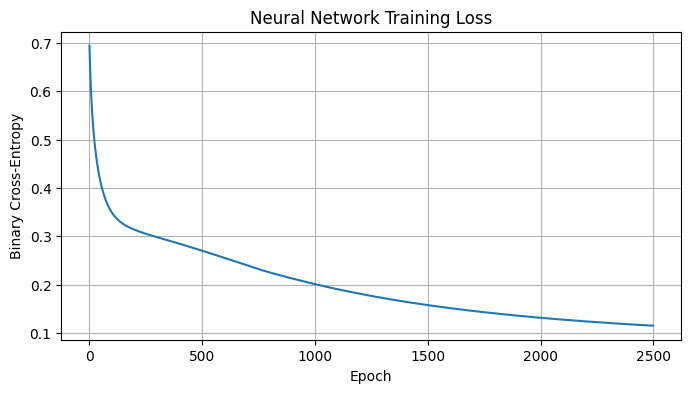

In [47]:

plt.figure(figsize=(8, 4))
plt.plot(loss_history)

plt.title("Neural Network Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.grid(True)
plt.show()


Visualize the decision boundary

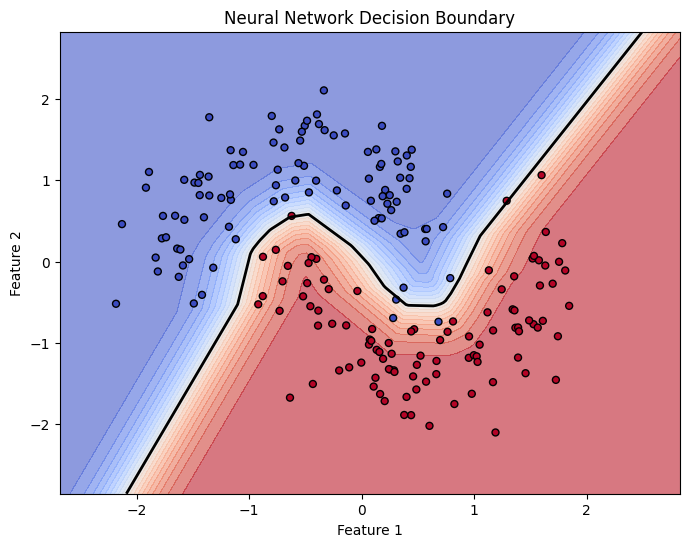

In [49]:

# STEP 7.6: Visualize the decision boundary

x_min, x_max = X_nn[:, 0].min() - 0.5, X_nn[:, 0].max() + 0.5
y_min, y_max = X_nn[:, 1].min() - 0.5, X_nn[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

grid_prob, _ = forward_propagation(grid, params)
Z = grid_prob.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, levels=20, cmap="coolwarm", alpha=0.6)
plt.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=2)

plt.scatter(
    Xte[:, 0], Xte[:, 1],
    c=yte.ravel(),
    cmap="coolwarm",
    edgecolors="black",
    s=25
)

plt.title("Neural Network Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


Understand underfitting and overfitting

In [50]:

# STEP 8.1: Generate data for the experiment

X_fit, y_fit = make_moons(
    n_samples=700,
    noise=0.30,
    random_state=7
)

X_fit_train, X_fit_test, y_fit_train, y_fit_test = train_test_split(
    X_fit, y_fit,
    test_size=0.30,
    random_state=7,
    stratify=y_fit
)

print("Training samples:", len(X_fit_train))
print("Test samples:", len(X_fit_test))


Training samples: 490
Test samples: 210


In [51]:

# STEP 8.2: Compare model complexity

architectures = {
    "Small": (2,),
    "Medium": (16,),
    "Large": (100, 100)
}

results = {}

for name, layers in architectures.items():

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_fit_train)
    X_test_scaled = scaler.transform(X_fit_test)

    model = MLPClassifier(
        hidden_layer_sizes=layers,
        activation="relu",
        solver="adam",
        max_iter=1500,
        random_state=7
    )

    model.fit(X_train_scaled, y_fit_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    train_acc = accuracy_score(y_fit_train, train_pred)
    test_acc = accuracy_score(y_fit_test, test_pred)

    results[name] = (train_acc, test_acc)

    print(
        f"{name:8s} | "
        f"Train accuracy: {train_acc:.3f} | "
        f"Test accuracy: {test_acc:.3f}"
    )


Small    | Train accuracy: 0.859 | Test accuracy: 0.843
Medium   | Train accuracy: 0.912 | Test accuracy: 0.905
Large    | Train accuracy: 0.927 | Test accuracy: 0.919


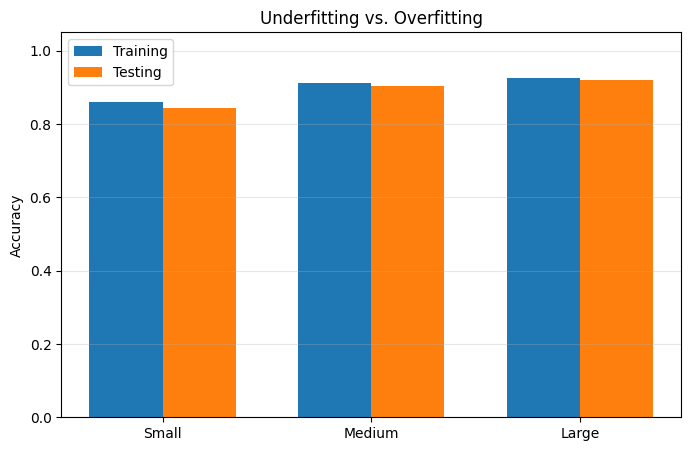

In [52]:

# STEP 8.3: Visualize generalization

names = list(results.keys())
train_scores = [results[n][0] for n in names]
test_scores = [results[n][1] for n in names]

positions = np.arange(len(names))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(positions - width/2, train_scores, width, label="Training")
plt.bar(positions + width/2, test_scores, width, label="Testing")

plt.xticks(positions, names)
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Underfitting vs. Overfitting")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()
